
# Gráficos para la tesis: cosmología phantom con difusión unimodular

Este notebook estudia el modelo

\[
p=-\rho-A\rho^\nu,
\qquad
Q=\alpha\rho,
\qquad
3H^2=(1+\alpha)\rho,
\]

con \(A>0\), \(\rho_0>0\) y \(\alpha>-1\). Se incluyen:

1. Gráficos de \(\rho(t)\), \(a(t)\), \(H(t)\) y \(\dot H(t)\) para \(\nu<0\) y \(\nu=0\).
2. Gráficos de \(\rho(t)\), \(a(t)\) y \(H(t)\) para los demás intervalos de \(\nu\).
3. Paneles diagnósticos de \(\dot H(t)\) y \(\omega_{\mathrm{eff}}(t)\).
4. Dos gráficos separados de \(t_s(\alpha)\): Big Rip \((1/2<\nu<1)\) y singularidad tipo III \((\nu>1)\).

Para \(\nu=0\),

\[
\dot H=\frac{A}{2}=\text{constante},
\]

lo que permite identificar de forma directa el comportamiento de tipo *Little Sibling of the Big Rip* en el límite \(t\to\infty\).


In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

FIG_DIR = Path("figures/tesis_phantom_ug")
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 8,
})

print(f"Las figuras se guardarán en: {FIG_DIR.resolve()}")

Las figuras se guardarán en: /Users/macbook/Usach/TesisxD/cosmo_singularities/notebooks/figures/tesis_phantom_ug



## 1. Soluciones analíticas y cantidades cosmológicas

Para \(\nu\neq 1/2\), la densidad está dada por

\[
\rho(t)=\left[
\rho_0^{1/2-\nu}
+\left(\frac12-\nu\right)
\frac{\sqrt{3}A}{\sqrt{1+\alpha}}(t-t_0)
\right]^{1/(1/2-\nu)}.
\]

Además,

\[
H=\sqrt{\frac{(1+\alpha)\rho}{3}},
\qquad
\dot H=\frac{A}{2}\rho^\nu,
\qquad
\omega_{\mathrm{eff}}
=-1-\frac{A}{1+\alpha}\rho^{\nu-1}.
\]


In [2]:
def _validate_parameters(A, alpha, rho0, a0=1.0):
    if A <= 0:
        raise ValueError("Se requiere A > 0.")
    if alpha <= -1:
        raise ValueError("Se requiere alpha > -1 para que H sea real.")
    if rho0 <= 0:
        raise ValueError("Se requiere rho0 > 0.")
    if a0 <= 0:
        raise ValueError("Se requiere a0 > 0.")


def rho_of_t(t, A, nu, alpha, rho0=1.0, t0=0.0):
    """Densidad analítica para el modelo Q = alpha*rho."""
    _validate_parameters(A=A, alpha=alpha, rho0=rho0)

    t = np.asarray(t, dtype=float)
    k = np.sqrt(3.0) * A / np.sqrt(1.0 + alpha)

    if np.isclose(nu, 0.5):
        return rho0 * np.exp(k * (t - t0))

    m = 0.5 - nu
    bracket = rho0**m + m * k * (t - t0)

    rho = np.full_like(t, np.nan, dtype=float)
    valid = bracket > 0.0
    rho[valid] = bracket[valid] ** (1.0 / m)
    return rho


def log_a_from_rho(rho, A, nu, alpha, rho0=1.0, a0=1.0):
    """Calcula ln(a) para evitar desbordamientos numéricos innecesarios."""
    _validate_parameters(A=A, alpha=alpha, rho0=rho0, a0=a0)

    rho = np.asarray(rho, dtype=float)
    log_a0 = np.log(a0)

    if np.isclose(nu, 1.0):
        return log_a0 + (1.0 + alpha) / (3.0 * A) * np.log(rho / rho0)

    return log_a0 + (1.0 + alpha) / (3.0 * A * (1.0 - nu)) * (
        rho ** (1.0 - nu) - rho0 ** (1.0 - nu)
    )


def a_from_rho(rho, A, nu, alpha, rho0=1.0, a0=1.0):
    """Factor de escala; devuelve NaN si exp(ln a) excede el rango de float."""
    log_a = log_a_from_rho(
        rho=rho,
        A=A,
        nu=nu,
        alpha=alpha,
        rho0=rho0,
        a0=a0,
    )

    max_log = np.log(1.0e200)  # límite gráfico seguro para escala logarítmica
    a = np.full_like(log_a, np.nan, dtype=float)
    valid = np.isfinite(log_a) & (log_a < max_log)
    a[valid] = np.exp(log_a[valid])
    return a


def H_from_rho(rho, alpha):
    if alpha <= -1:
        raise ValueError("Se requiere alpha > -1 para que H sea real.")
    rho = np.asarray(rho, dtype=float)
    return np.sqrt((1.0 + alpha) * rho / 3.0)


def Hdot_from_rho(rho, A, nu):
    rho = np.asarray(rho, dtype=float)
    return 0.5 * A * rho**nu


def w_eff_from_rho(rho, A, nu, alpha):
    if alpha <= -1:
        raise ValueError("Se requiere alpha > -1.")
    rho = np.asarray(rho, dtype=float)
    return -1.0 - (A / (1.0 + alpha)) * rho ** (nu - 1.0)


def singular_time(A, nu, alpha, rho0=1.0, t0=0.0):
    """Tiempo singular futuro para nu > 1/2; infinito en otro caso."""
    _validate_parameters(A=A, alpha=alpha, rho0=rho0)

    if nu <= 0.5:
        return np.inf

    return t0 + (
        rho0 ** (0.5 - nu)
        * np.sqrt(1.0 + alpha)
        / (np.sqrt(3.0) * A * (nu - 0.5))
    )


def make_time_grid(
    A,
    nu,
    alpha,
    rho0=1.0,
    t0=0.0,
    t_max=8.0,
    n_points=1200,
    singular_fraction=0.97,
):
    """Construye una grilla temporal sin evaluar exactamente en t_s."""
    ts = singular_time(A=A, nu=nu, alpha=alpha, rho0=rho0, t0=t0)

    if np.isfinite(ts):
        t_end = t0 + singular_fraction * (ts - t0)
    else:
        t_end = t_max

    return np.linspace(t0, t_end, n_points), ts

In [ ]:
# Comprobaciones rápidas de consistencia
A_test = 1.0
rho_test = np.array([1.0, 2.0, 4.0])

assert np.allclose(Hdot_from_rho(rho_test, A=A_test, nu=0.0), 0.5)
assert np.isinf(singular_time(A=1.0, nu=0.0, alpha=0.0))
assert np.isfinite(singular_time(A=1.0, nu=0.75, alpha=0.0))

print("Comprobaciones analíticas superadas.")


## 2. Funciones para los gráficos

Los colores representan los distintos valores de \(\nu\), mientras que los estilos de línea representan los valores de \(\alpha\). Para los casos con singularidad en tiempo finito, la evolución se grafica hasta una fracción del tiempo singular, evitando evaluar exactamente en \(t=t_s\).


In [3]:
def _parameter_styles(nu_values, alpha_values):
    default_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    line_styles = ["-", "--", ":", "-."]

    nu_colors = {
        nu: default_colors[i % len(default_colors)]
        for i, nu in enumerate(nu_values)
    }
    alpha_styles = {
        alpha: line_styles[i % len(line_styles)]
        for i, alpha in enumerate(alpha_values)
    }
    return nu_colors, alpha_styles


def _add_parameter_legends(ax, nu_values, alpha_values, nu_colors, alpha_styles):
    nu_handles = [
        Line2D([0], [0], color=nu_colors[nu], linewidth=2.0, label=rf"$\nu={nu:g}$")
        for nu in nu_values
    ]
    alpha_handles = [
        Line2D(
            [0],
            [0],
            color="black",
            linestyle=alpha_styles[alpha],
            linewidth=2.0,
            label=rf"$\alpha={alpha:g}$",
        )
        for alpha in alpha_values
    ]

    first_legend = ax.legend(
        handles=nu_handles,
        title=r"Valores de $\nu$",
        loc="upper left",
        fontsize=8,
        title_fontsize=9,
    )
    ax.add_artist(first_legend)
    ax.legend(
        handles=alpha_handles,
        title=r"Valores de $\alpha$",
        loc="lower right",
        fontsize=8,
        title_fontsize=9,
    )


def plot_background_interval(
    nu_values,
    alpha_values,
    title,
    filename,
    include_hdot=False,
    A=1.0,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
    t_max=8.0,
    n_points=1200,
    singular_fraction=0.97,
    a_log_scale=True,
):
    """Grafica rho, a, H y, opcionalmente, Hdot."""
    if len(nu_values) == 0 or len(alpha_values) == 0:
        raise ValueError("nu_values y alpha_values no pueden estar vacíos.")

    n_panels = 4 if include_hdot else 3

    if include_hdot:
        fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.3))
        axes = axes.ravel()
    else:
        fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.6))

    nu_colors, alpha_styles = _parameter_styles(nu_values, alpha_values)
    hdot_zero_plotted = False

    for nu in nu_values:
        for alpha in alpha_values:
            t, _ = make_time_grid(
                A=A,
                nu=nu,
                alpha=alpha,
                rho0=rho0,
                t0=t0,
                t_max=t_max,
                n_points=n_points,
                singular_fraction=singular_fraction,
            )

            rho = rho_of_t(t, A=A, nu=nu, alpha=alpha, rho0=rho0, t0=t0)
            a = a_from_rho(
                rho,
                A=A,
                nu=nu,
                alpha=alpha,
                rho0=rho0,
                a0=a0,
            )
            H = H_from_rho(rho, alpha=alpha)
            Hdot = Hdot_from_rho(rho, A=A, nu=nu)

            color = nu_colors[nu]
            linestyle = alpha_styles[alpha]

            axes[0].plot(t, rho, color=color, linestyle=linestyle, linewidth=1.8)
            axes[1].plot(t, a, color=color, linestyle=linestyle, linewidth=1.8)
            axes[2].plot(t, H, color=color, linestyle=linestyle, linewidth=1.8)

            if include_hdot:
                if np.isclose(nu, 0.0):
                    # Para nu=0, Hdot=A/2 y todas las curvas coinciden.
                    if not hdot_zero_plotted:
                        axes[3].plot(
                            t,
                            Hdot,
                            color=color,
                            linewidth=2.2,
                            label=rf"$\dot H=A/2={A/2:g}$",
                        )
                        hdot_zero_plotted = True
                else:
                    axes[3].plot(
                        t,
                        Hdot,
                        color=color,
                        linestyle=linestyle,
                        linewidth=1.8,
                    )

    axes[0].set_title("Densidad de energía")
    axes[1].set_title("Factor de escala")
    axes[2].set_title("Parámetro de Hubble")

    axes[0].set_ylabel(r"$\rho(t)$")
    axes[1].set_ylabel(r"$a(t)$")
    axes[2].set_ylabel(r"$H(t)$")

    axes[0].set_yscale("log")
    if a_log_scale:
        axes[1].set_yscale("log")
    axes[2].set_yscale("log")

    if include_hdot:
        axes[3].set_title("Derivada del parámetro de Hubble")
        axes[3].set_ylabel(r"$\dot H(t)$")

        all_nu_zero = np.all(np.isclose(np.asarray(nu_values, dtype=float), 0.0))
        if all_nu_zero:
            axes[3].legend(loc="best")
            axes[3].set_ylim(0.45 * A, 0.55 * A)
        else:
            axes[3].set_yscale("log")

    for ax in axes[:n_panels]:
        ax.set_xlabel(r"$t$")
        ax.grid(True, which="both", alpha=0.3)

    _add_parameter_legends(
        ax=axes[0],
        nu_values=nu_values,
        alpha_values=alpha_values,
        nu_colors=nu_colors,
        alpha_styles=alpha_styles,
    )

    fig.suptitle(title, fontsize=14, y=0.99)
    plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.96])

    output_path = FIG_DIR / filename
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Figura guardada en: {output_path}")


def plot_hdot_weff_interval(
    nu_values,
    alpha_values,
    title,
    filename,
    A=1.0,
    rho0=1.0,
    t0=0.0,
    t_max=8.0,
    n_points=1200,
    singular_fraction=0.97,
):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
    nu_colors, alpha_styles = _parameter_styles(nu_values, alpha_values)

    for nu in nu_values:
        for alpha in alpha_values:
            t, _ = make_time_grid(
                A=A,
                nu=nu,
                alpha=alpha,
                rho0=rho0,
                t0=t0,
                t_max=t_max,
                n_points=n_points,
                singular_fraction=singular_fraction,
            )
            rho = rho_of_t(t, A=A, nu=nu, alpha=alpha, rho0=rho0, t0=t0)
            Hdot = Hdot_from_rho(rho, A=A, nu=nu)
            w_eff = w_eff_from_rho(rho, A=A, nu=nu, alpha=alpha)

            color = nu_colors[nu]
            linestyle = alpha_styles[alpha]

            axes[0].plot(t, Hdot, color=color, linestyle=linestyle, linewidth=1.8)
            axes[1].plot(t, w_eff, color=color, linestyle=linestyle, linewidth=1.8)

    axes[0].set_title(r"Evolución de $\dot H$")
    axes[1].set_title(r"Evolución de $\omega_{\mathrm{eff}}$")
    axes[0].set_ylabel(r"$\dot H(t)$")
    axes[1].set_ylabel(r"$\omega_{\mathrm{eff}}(t)$")
    axes[0].set_yscale("log")
    axes[1].axhline(-1.0, color="black", linestyle="--", linewidth=1.0)

    for ax in axes:
        ax.set_xlabel(r"$t$")
        ax.grid(True, which="both", alpha=0.3)

    _add_parameter_legends(
        ax=axes[0],
        nu_values=nu_values,
        alpha_values=alpha_values,
        nu_colors=nu_colors,
        alpha_styles=alpha_styles,
    )

    fig.suptitle(title, fontsize=14, y=1.02)
    plt.tight_layout()

    output_path = FIG_DIR / filename
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Figura guardada en: {output_path}")


## 3. Parámetros de los gráficos

Se utilizan valores pequeños negativos, nulos y positivos de \(\alpha\). El valor \(\alpha=0\) representa el límite sin difusión y permite una comparación directa.


In [4]:
A = 1.0
RHO0 = 1.0
A0 = 1.0
T0 = 0.0

ALPHA_VALUES = [-0.3, 0.0, 0.3]

print("A =", A)
print("rho0 =", RHO0)
print("a0 =", A0)
print("t0 =", T0)
print("alpha_values =", ALPHA_VALUES)

A = 1.0
rho0 = 1.0
a0 = 1.0
t0 = 0.0
alpha_values = [-0.3, 0.0, 0.3]



## 4. Evolución para \(\nu<0\): \(\rho(t)\), \(a(t)\), \(H(t)\) y \(\dot H(t)\)

En este intervalo,

\[
\dot H=\frac{A}{2}\rho^\nu
=\frac{A}{2\rho^{|\nu|}},
\]

por lo que \(\dot H\to0\) cuando \(\rho\to\infty\). La densidad y el parámetro de Hubble aumentan solamente en el límite \(t\to\infty\), mientras que la tasa de crecimiento de \(H\) tiende a cero.


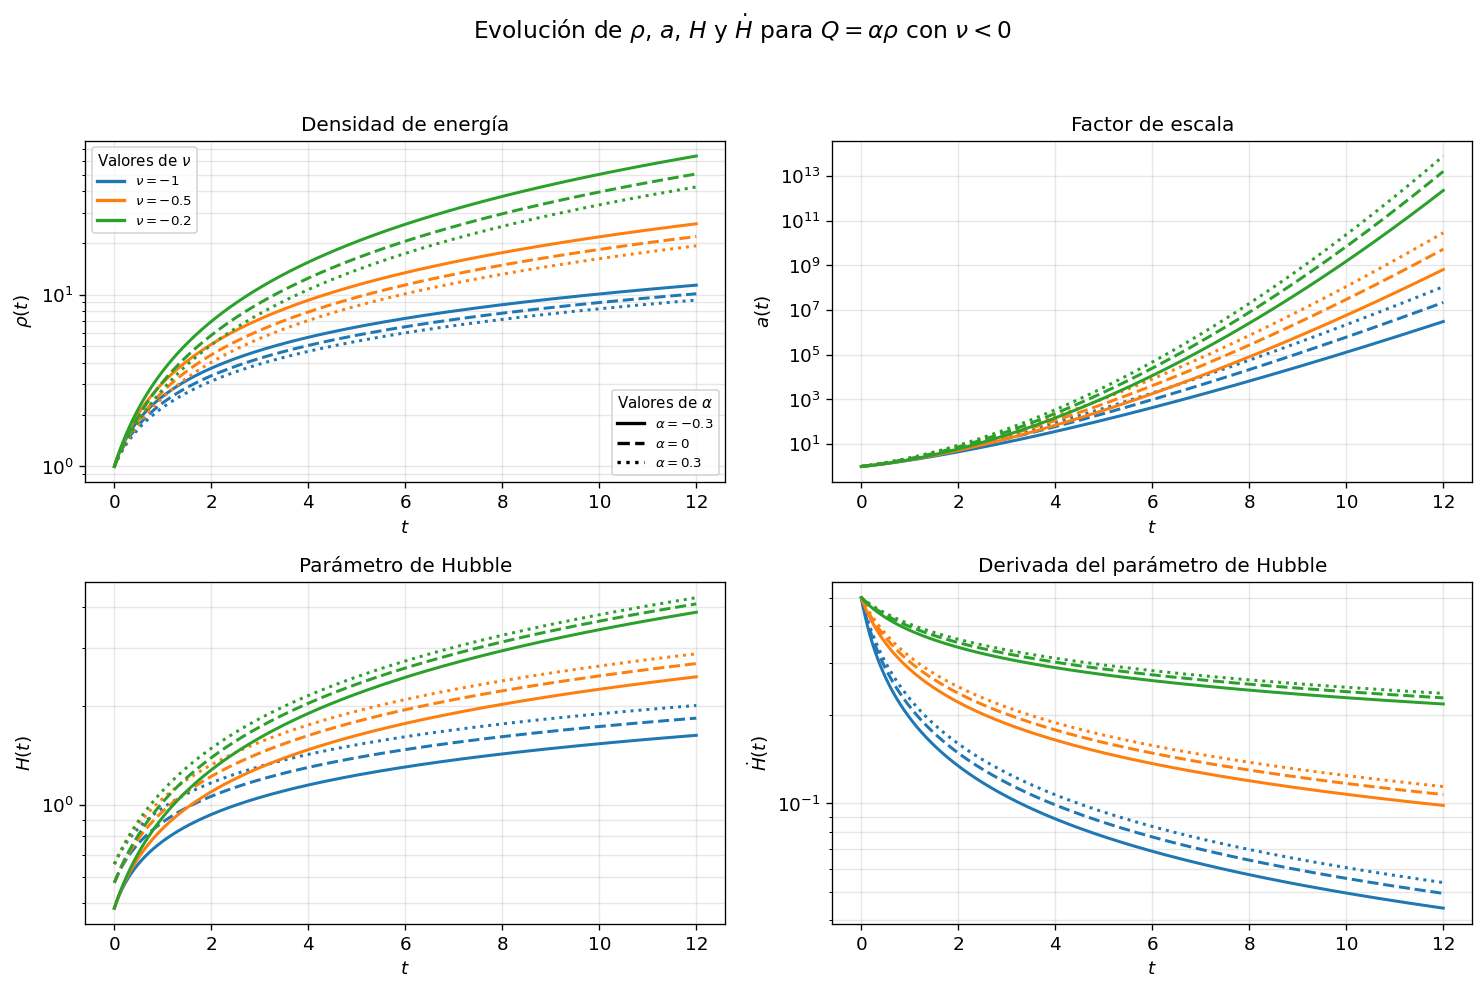

Figura guardada en: figures/tesis_phantom_ug/ug_intervalo_nu_menor_0_con_hdot.pdf


In [5]:
plot_background_interval(
    nu_values=[-1.0, -0.5, -0.2],
    alpha_values=ALPHA_VALUES,
    title=(
        r"Evolución de $\rho$, $a$, $H$ y $\dot H$ "
        r"para $Q=\alpha\rho$ con $\nu<0$"
    ),
    filename="ug_intervalo_nu_menor_0_con_hdot.pdf",
    include_hdot=True,
    A=A,
    rho0=RHO0,
    a0=A0,
    t0=T0,
    t_max=12.0,
)


## 5. Evolución para \(\nu=0\): Little Sibling of the Big Rip

Para \(\nu=0\),

\[
\dot H=\frac{A}{2},
\]

independientemente de \(\rho\) y de \(\alpha\). En consecuencia, \(H\), \(\rho\) y \(a\) divergen cuando \(t\to\infty\), mientras que \(\dot H\) permanece finita y constante. El panel inferior derecho muestra una sola curva porque todas las elecciones de \(\alpha\) producen exactamente el mismo valor de \(\dot H\).


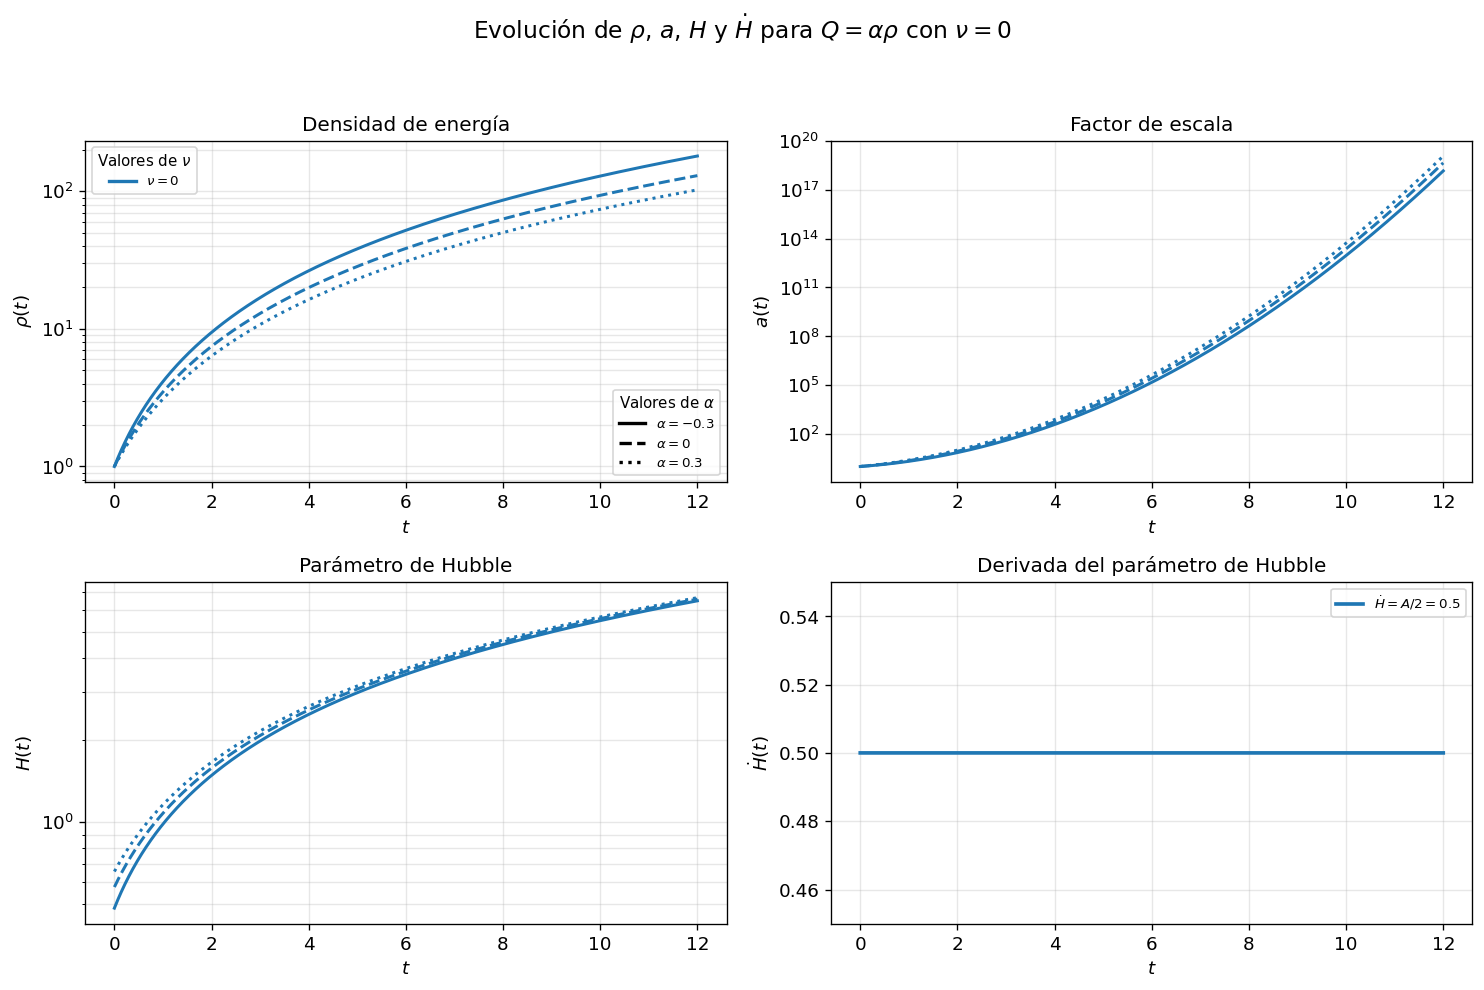

Figura guardada en: figures/tesis_phantom_ug/ug_intervalo_nu_igual_0_con_hdot.pdf


In [6]:
plot_background_interval(
    nu_values=[0.0],
    alpha_values=ALPHA_VALUES,
    title=(
        r"Evolución de $\rho$, $a$, $H$ y $\dot H$ "
        r"para $Q=\alpha\rho$ con $\nu=0$"
    ),
    filename="ug_intervalo_nu_igual_0_con_hdot.pdf",
    include_hdot=True,
    A=A,
    rho0=RHO0,
    a0=A0,
    t0=T0,
    t_max=12.0,
)


## 6. Evolución para los demás intervalos de \(\nu\)

En estos casos se mantienen los tres paneles originales: \(\rho(t)\), \(a(t)\) y \(H(t)\).


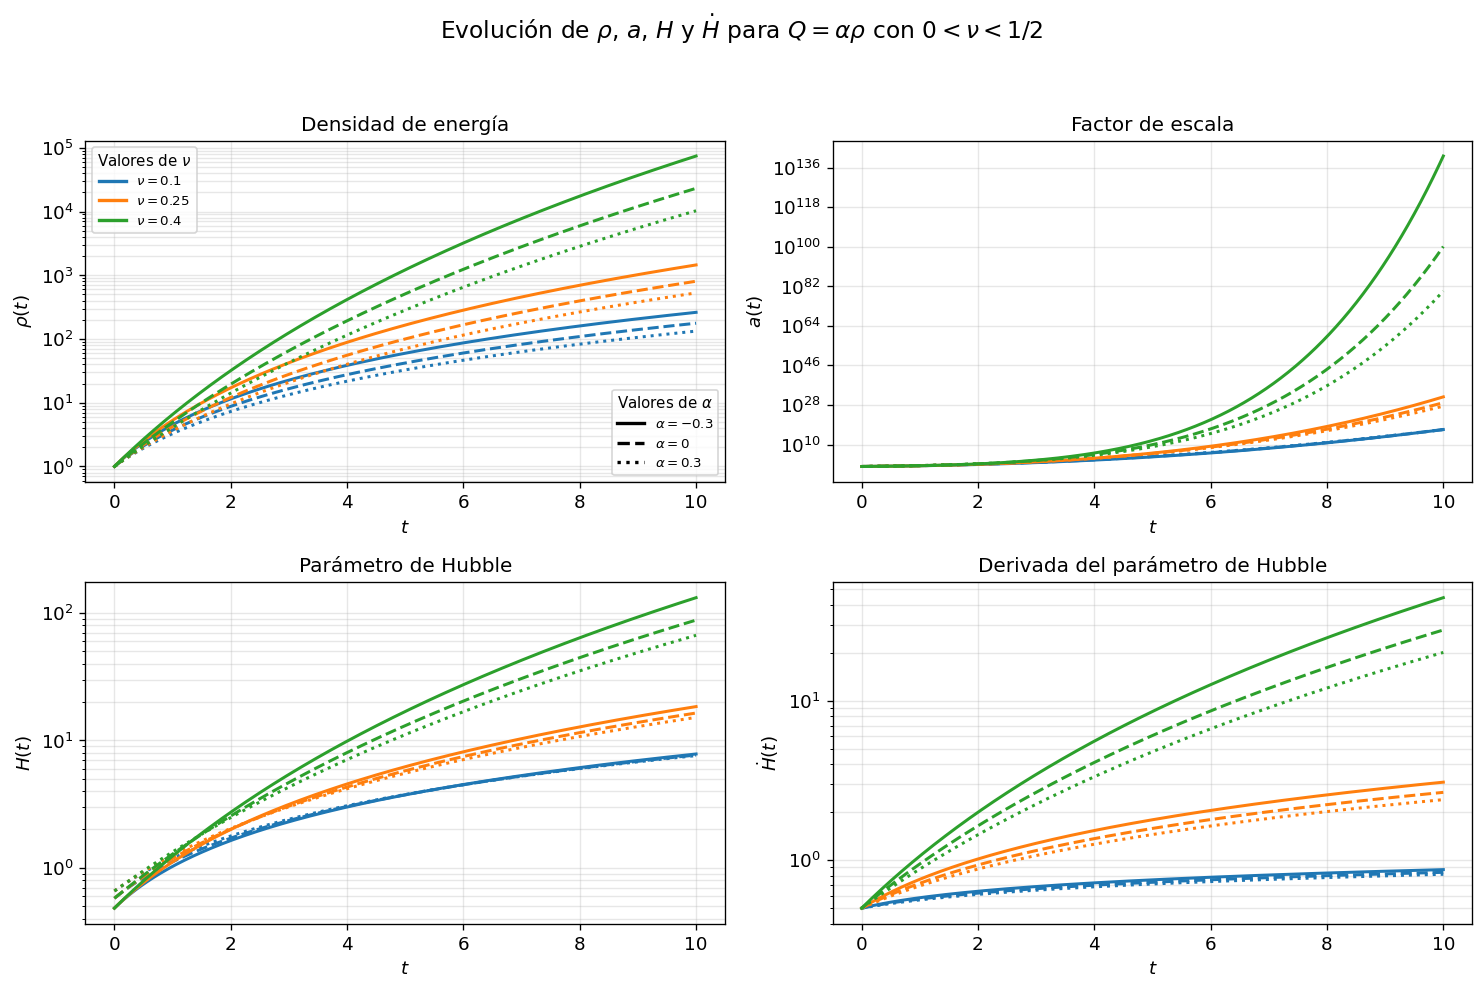

Figura guardada en: figures/tesis_phantom_ug/ug_intervalo_0_menor_nu_menor_1_2_con_hdot.pdf


In [23]:
plot_background_interval(
    nu_values=[0.1, 0.25, 0.4],
    alpha_values=ALPHA_VALUES,
    title=(
        r"Evolución de $\rho$, $a$, $H$ y $\dot H$ "
        r"para $Q=\alpha\rho$ con $0<\nu<1/2$"
    ),
    filename="ug_intervalo_0_menor_nu_menor_1_2_con_hdot.pdf",
    include_hdot=True,
    A=A,
    rho0=RHO0,
    a0=A0,
    t0=T0,
    t_max=10.0,
)

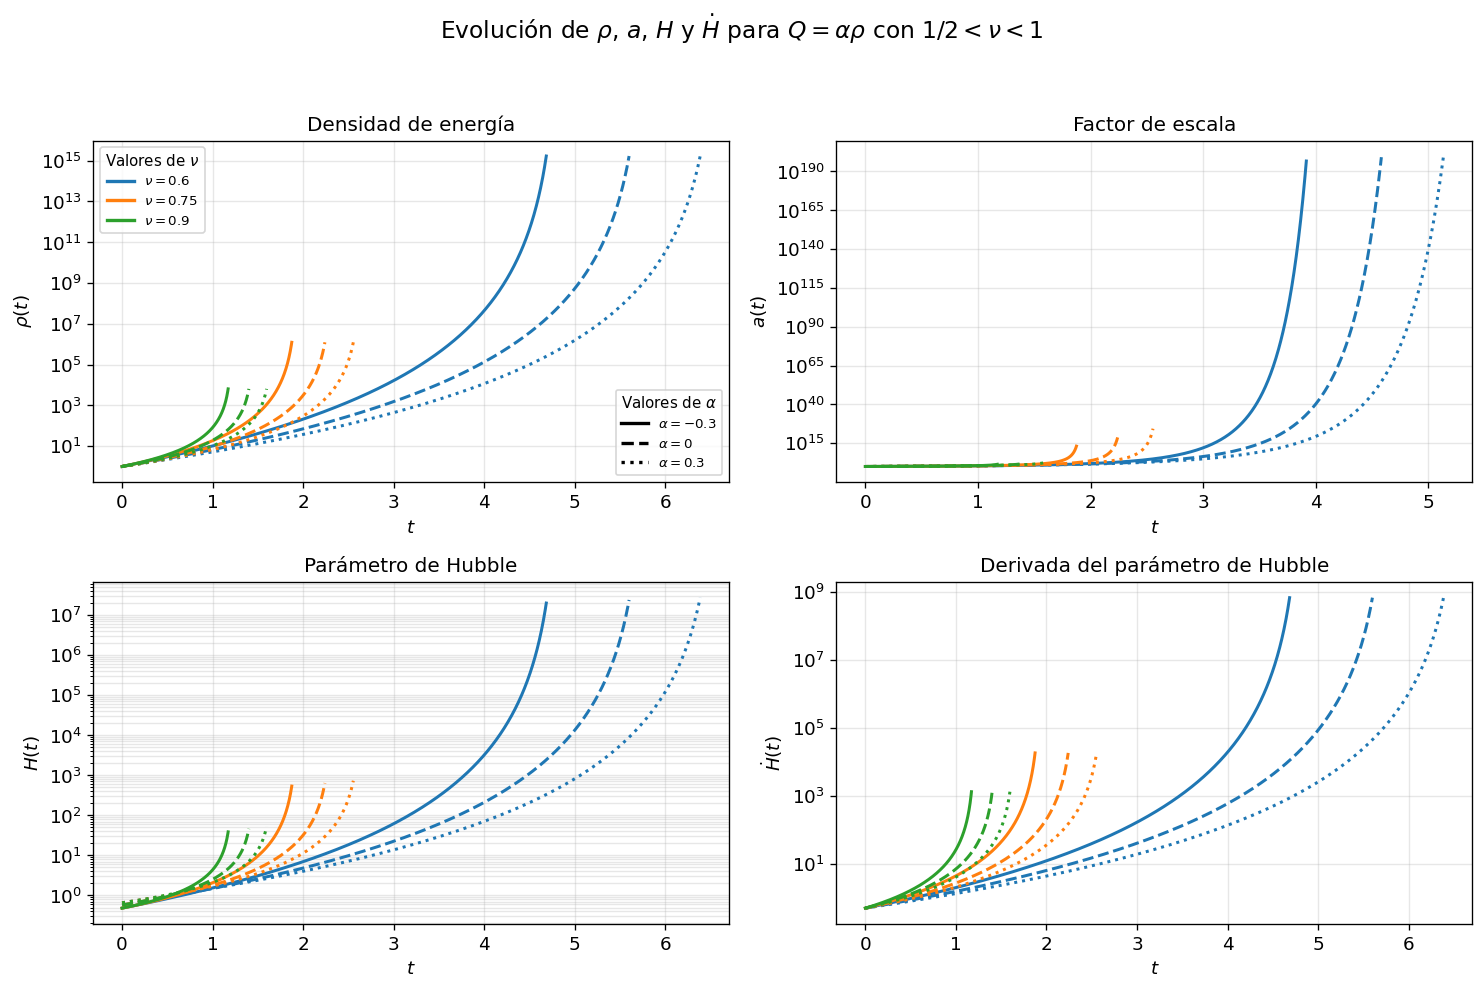

Figura guardada en: figures/tesis_phantom_ug/ug_intervalo_1_2_menor_nu_menor_1_con_hdot.pdf


In [24]:
plot_background_interval(
    nu_values=[0.6, 0.75, 0.9],
    alpha_values=ALPHA_VALUES,
    title=(
        r"Evolución de $\rho$, $a$, $H$ y $\dot H$ "
        r"para $Q=\alpha\rho$ con $1/2<\nu<1$"
    ),
    filename="ug_intervalo_1_2_menor_nu_menor_1_con_hdot.pdf",
    include_hdot=True,
    A=A,
    rho0=RHO0,
    a0=A0,
    t0=T0,
    singular_fraction=0.97,
)

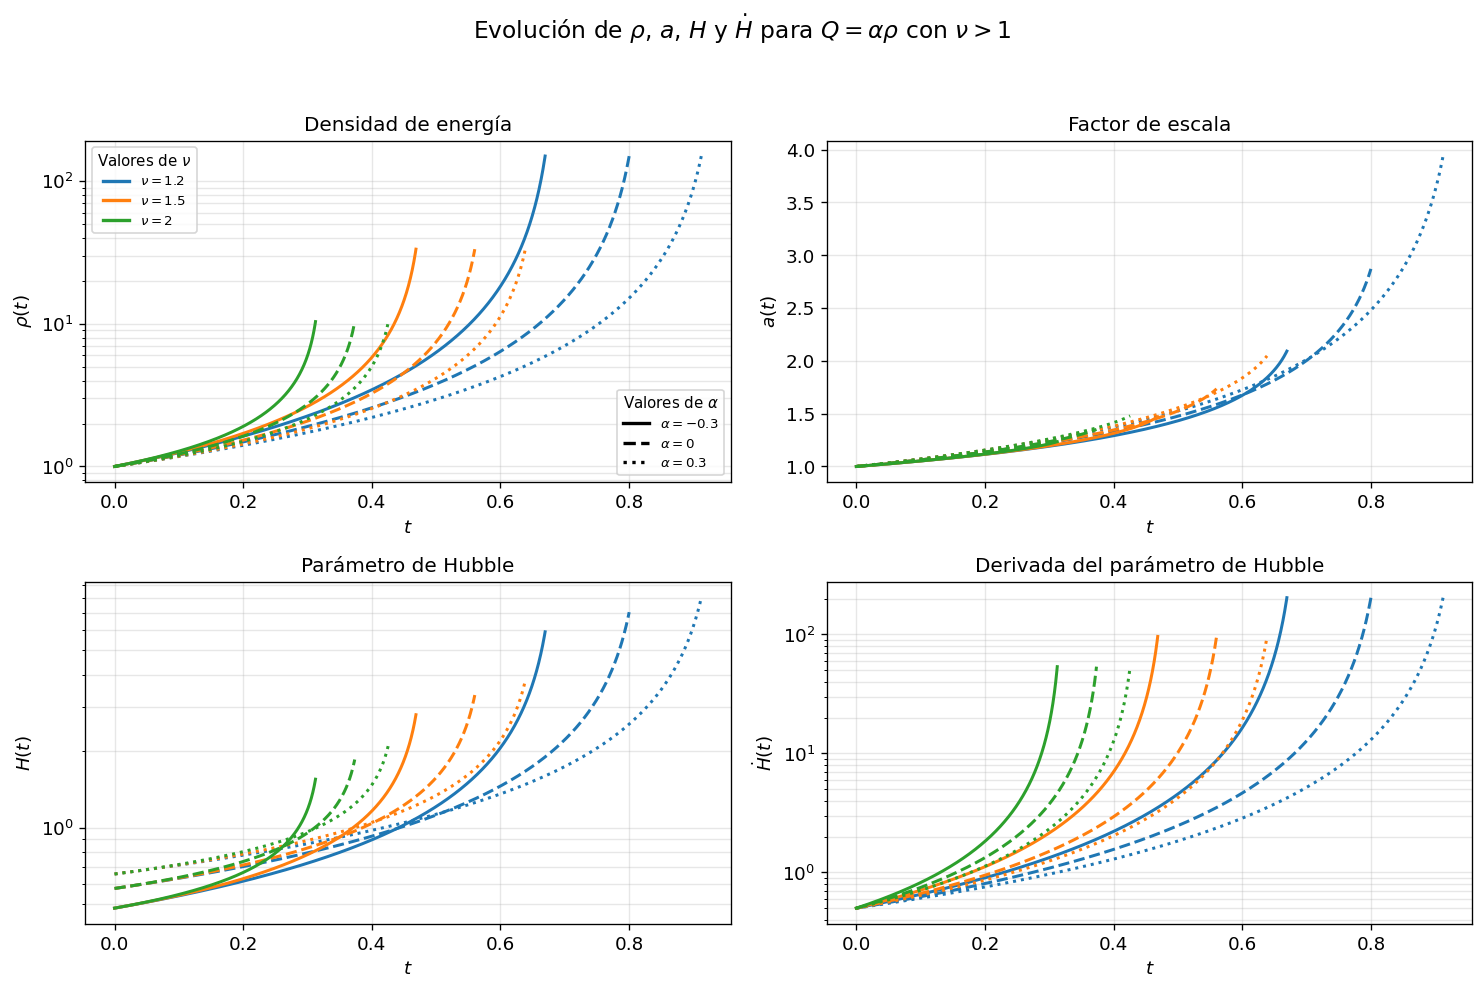

Figura guardada en: figures/tesis_phantom_ug/ug_intervalo_nu_mayor_1_con_hdot.pdf


In [25]:
plot_background_interval(
    nu_values=[1.2, 1.5, 2.0],
    alpha_values=ALPHA_VALUES,
    title=(
        r"Evolución de $\rho$, $a$, $H$ y $\dot H$ "
        r"para $Q=\alpha\rho$ con $\nu>1$"
    ),
    filename="ug_intervalo_nu_mayor_1_con_hdot.pdf",
    include_hdot=True,
    A=A,
    rho0=RHO0,
    a0=A0,
    t0=T0,
    singular_fraction=0.97,
    a_log_scale=False,
)


## 7. Diagnóstico adicional: \(\dot H(t)\) y \(\omega_{\mathrm{eff}}(t)\)

La ecuación de estado efectiva se define cinemáticamente mediante

\[
\omega_{\mathrm{eff}}=-1-\frac{2\dot H}{3H^2}
=-1-\frac{A}{1+\alpha}\rho^{\nu-1}.
\]

Los siguientes paneles son opcionales y complementan los gráficos principales.


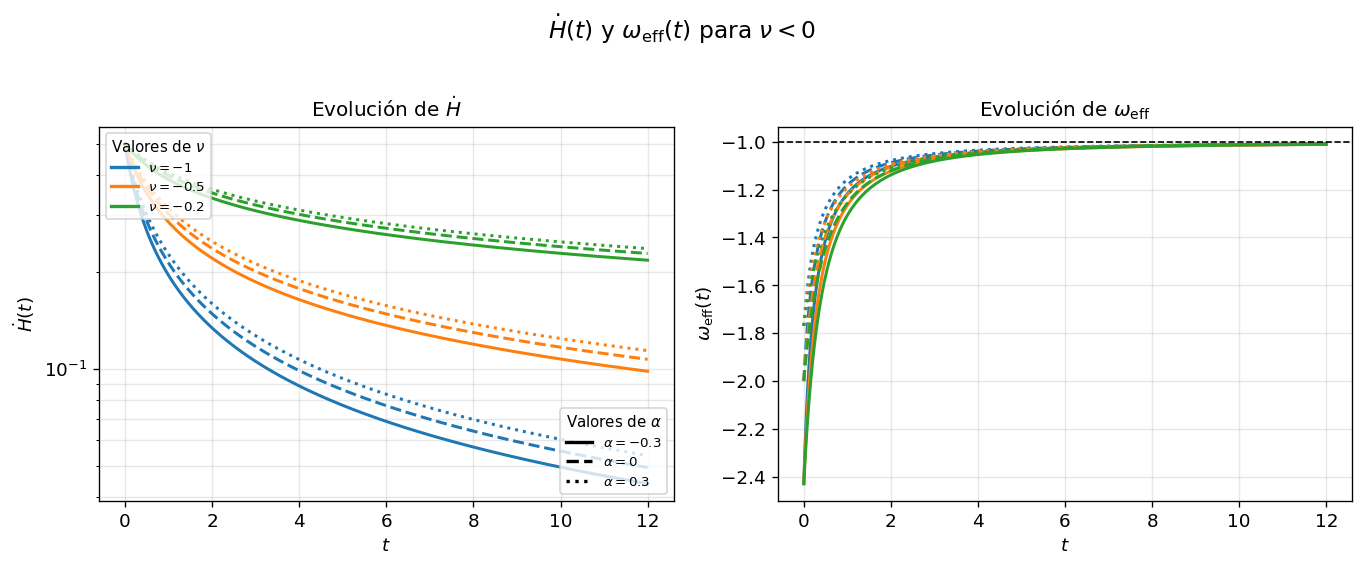

Figura guardada en: figures/tesis_phantom_ug/ug_hdot_weff_nu_menor_0.pdf


In [10]:
plot_hdot_weff_interval(
    nu_values=[-1.0, -0.5, -0.2],
    alpha_values=ALPHA_VALUES,
    title=r"$\dot H(t)$ y $\omega_{\mathrm{eff}}(t)$ para $\nu<0$",
    filename="ug_hdot_weff_nu_menor_0.pdf",
    A=A,
    rho0=RHO0,
    t0=T0,
    t_max=12.0,
)

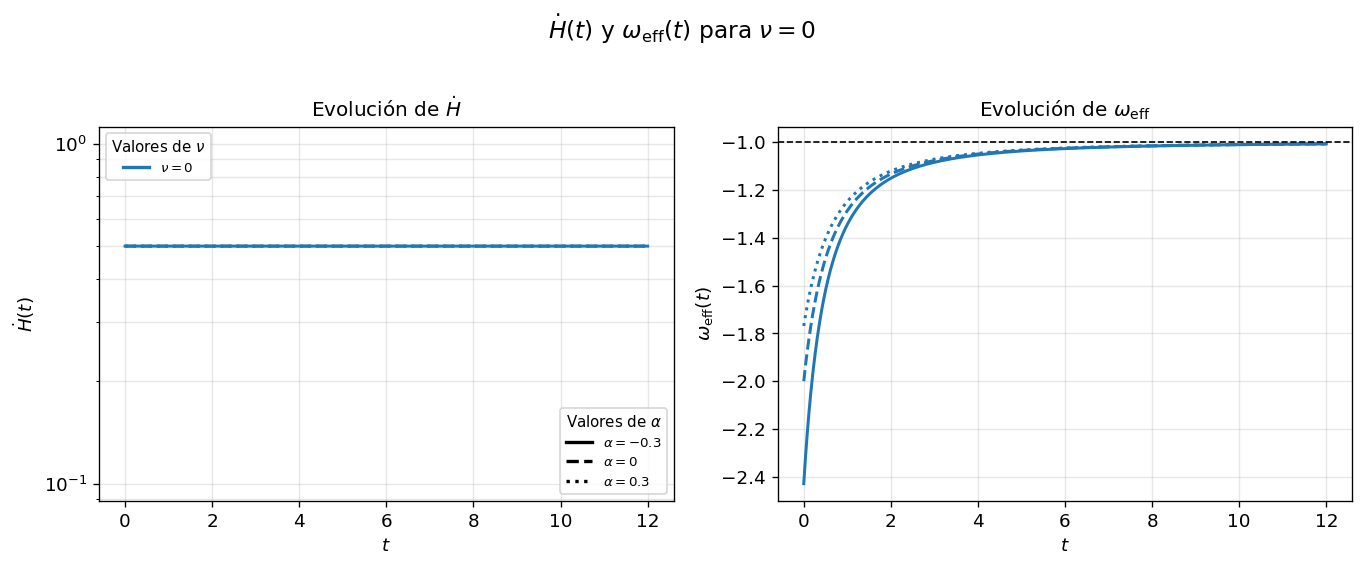

Figura guardada en: figures/tesis_phantom_ug/ug_hdot_weff_nu_igual_0.pdf


In [11]:
plot_hdot_weff_interval(
    nu_values=[0.0],
    alpha_values=ALPHA_VALUES,
    title=r"$\dot H(t)$ y $\omega_{\mathrm{eff}}(t)$ para $\nu=0$",
    filename="ug_hdot_weff_nu_igual_0.pdf",
    A=A,
    rho0=RHO0,
    t0=T0,
    t_max=12.0,
)


## 8. Tiempo singular \(t_s(\alpha)\)

Para \(\nu>1/2\),

\[
t_s=t_0+
\frac{\rho_0^{1/2-\nu}\sqrt{1+\alpha}}
{\sqrt{3}A(\nu-1/2)}.
\]

Se generan dos figuras independientes:

- \(1/2<\nu<1\): singularidad tipo I o Big Rip.
- \(\nu>1\): singularidad tipo III.


In [12]:
def plot_singular_time_vs_alpha(
    nu_values,
    title,
    filename,
    alpha_min=-0.8,
    alpha_max=3.0,
    n_alpha=500,
    A=1.0,
    rho0=1.0,
    t0=0.0,
):
    if alpha_min <= -1:
        raise ValueError("alpha_min debe ser mayor que -1.")
    if any(nu <= 0.5 for nu in nu_values):
        raise ValueError("Todos los valores de nu deben satisfacer nu > 1/2.")

    alpha_grid = np.linspace(alpha_min, alpha_max, n_alpha)
    fig, ax = plt.subplots(figsize=(8.2, 5.2))

    for nu in nu_values:
        ts_values = np.array([
            singular_time(
                A=A,
                nu=nu,
                alpha=alpha,
                rho0=rho0,
                t0=t0,
            )
            for alpha in alpha_grid
        ])
        ax.plot(alpha_grid, ts_values, linewidth=2.0, label=rf"$\nu={nu:g}$")

    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(r"$t_s$")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(title=r"Valor de $\nu$")
    fig.tight_layout()

    output_path = FIG_DIR / filename
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Figura guardada en: {output_path}")


### 8.1 Big Rip: \(1/2<\nu<1\)

En este intervalo, \(\rho\), \(H\), \(|p|\) y \(a\) divergen cuando \(t\to t_s^-\).


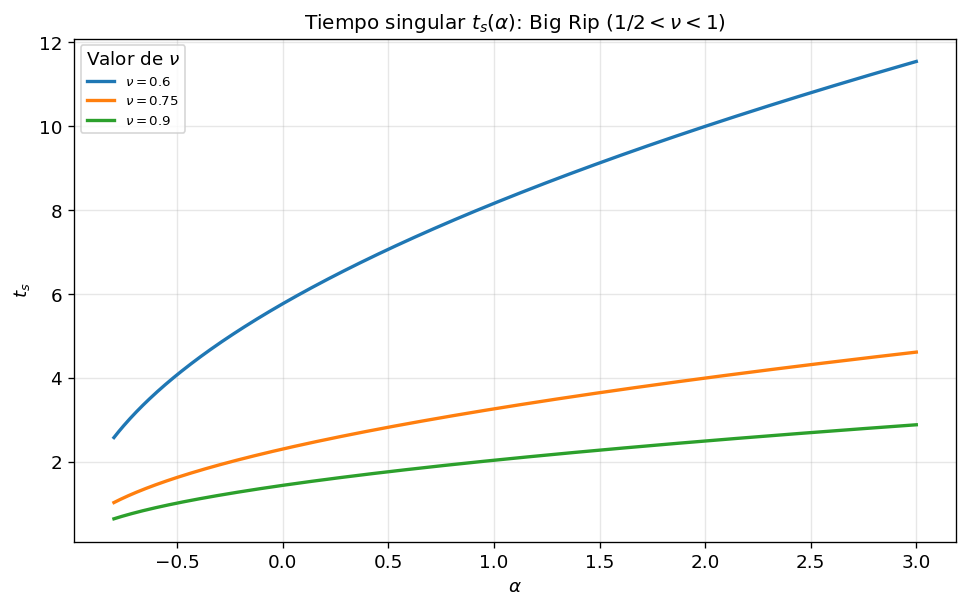

Figura guardada en: figures/tesis_phantom_ug/ug_tiempo_singular_vs_alpha_big_rip.pdf


In [13]:
plot_singular_time_vs_alpha(
    nu_values=[0.6, 0.75, 0.9],
    title=(
        r"Tiempo singular $t_s(\alpha)$: Big Rip "
        r"$(1/2<\nu<1)$"
    ),
    filename="ug_tiempo_singular_vs_alpha_big_rip.pdf",
    alpha_min=-0.8,
    alpha_max=3.0,
    A=A,
    rho0=RHO0,
    t0=T0,
)


### 8.2 Singularidad tipo III: \(\nu>1\)

En este intervalo, \(\rho\), \(H\) y \(|p|\) divergen en tiempo finito, mientras que el factor de escala se aproxima a un valor finito \(a_s\).


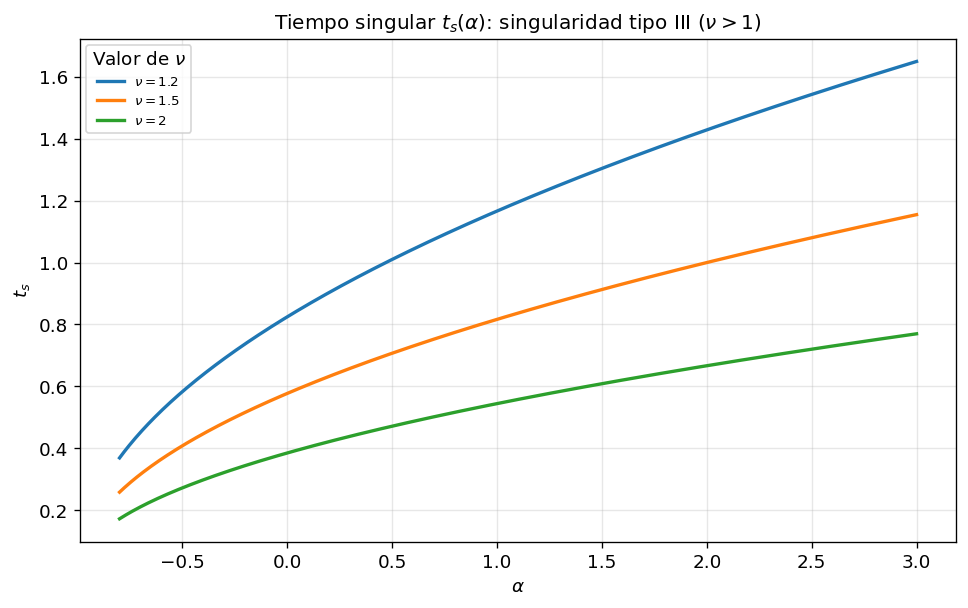

Figura guardada en: figures/tesis_phantom_ug/ug_tiempo_singular_vs_alpha_tipo_III.pdf


In [14]:
plot_singular_time_vs_alpha(
    nu_values=[1.2, 1.5, 2.0],
    title=(
        r"Tiempo singular $t_s(\alpha)$: singularidad tipo III "
        r"$(\nu>1)$"
    ),
    filename="ug_tiempo_singular_vs_alpha_tipo_III.pdf",
    alpha_min=-0.8,
    alpha_max=3.0,
    A=A,
    rho0=RHO0,
    t0=T0,
)

In [21]:
def plot_singular_time_combined(
    nu_values_big_rip,
    nu_values_type_iii,
    filename,
    alpha_min=-0.8,
    alpha_max=3.0,
    n_alpha=400,
    A=1.0,
    rho0=1.0,
    t0=0.0,
):
    """
    Genera una sola figura con dos paneles:

    Panel izquierdo:
        Tiempo singular para 1/2 < nu < 1
        Singularidad tipo I o Big Rip.

    Panel derecho:
        Tiempo singular para nu > 1
        Singularidad tipo III.
    """

    alpha_grid = np.linspace(
        alpha_min,
        alpha_max,
        n_alpha,
    )

    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(13, 5),
        sharex=True,
    )

    # ==========================================================
    # Panel izquierdo: Big Rip, 1/2 < nu < 1
    # ==========================================================

    for nu in nu_values_big_rip:

        ts_values = np.array(
            [
                singular_time(
                    A=A,
                    nu=nu,
                    alpha=alpha,
                    rho0=rho0,
                    t0=t0,
                )
                for alpha in alpha_grid
            ],
            dtype=float,
        )

        valid_mask = np.isfinite(ts_values)

        axes[0].plot(
            alpha_grid[valid_mask],
            ts_values[valid_mask],
            linewidth=2,
            label=rf"$\nu={nu:g}$",
        )

    axes[0].set_title(
        r"Big Rip: $1/2<\nu<1$"
    )

    axes[0].set_xlabel(r"$\alpha$")
    axes[0].set_ylabel(r"$t_s(\alpha)$")

    axes[0].grid(
        True,
        which="both",
        alpha=0.3,
    )

    axes[0].legend(
        fontsize=9,
        loc="best",
    )

    # ==========================================================
    # Panel derecho: singularidad tipo III, nu > 1
    # ==========================================================

    for nu in nu_values_type_iii:

        ts_values = np.array(
            [
                singular_time(
                    A=A,
                    nu=nu,
                    alpha=alpha,
                    rho0=rho0,
                    t0=t0,
                )
                for alpha in alpha_grid
            ],
            dtype=float,
        )

        valid_mask = np.isfinite(ts_values)

        axes[1].plot(
            alpha_grid[valid_mask],
            ts_values[valid_mask],
            linewidth=2,
            label=rf"$\nu={nu:g}$",
        )


    axes[1].set_title(
        r"Singularidad tipo III: $\nu>1$"
    )

    axes[1].set_xlabel(r"$\alpha$")
    axes[1].set_ylabel(r"$t_s(\alpha)$")

    axes[1].grid(
        True,
        which="both",
        alpha=0.3,
    )

    axes[1].legend(
        fontsize=9,
        loc="best",
    )

    # ==========================================================
    # Configuración general de la figura
    # ==========================================================

    fig.suptitle(
        r"Dependencia del tiempo de ruptura($t_s$) con el parámetro "
        r"de difusión $\alpha$",
        fontsize=14,
        y=1.02,
    )

    plt.tight_layout()

    output_path = FIG_DIR / filename

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    print(f"Figura guardada en: {output_path}")

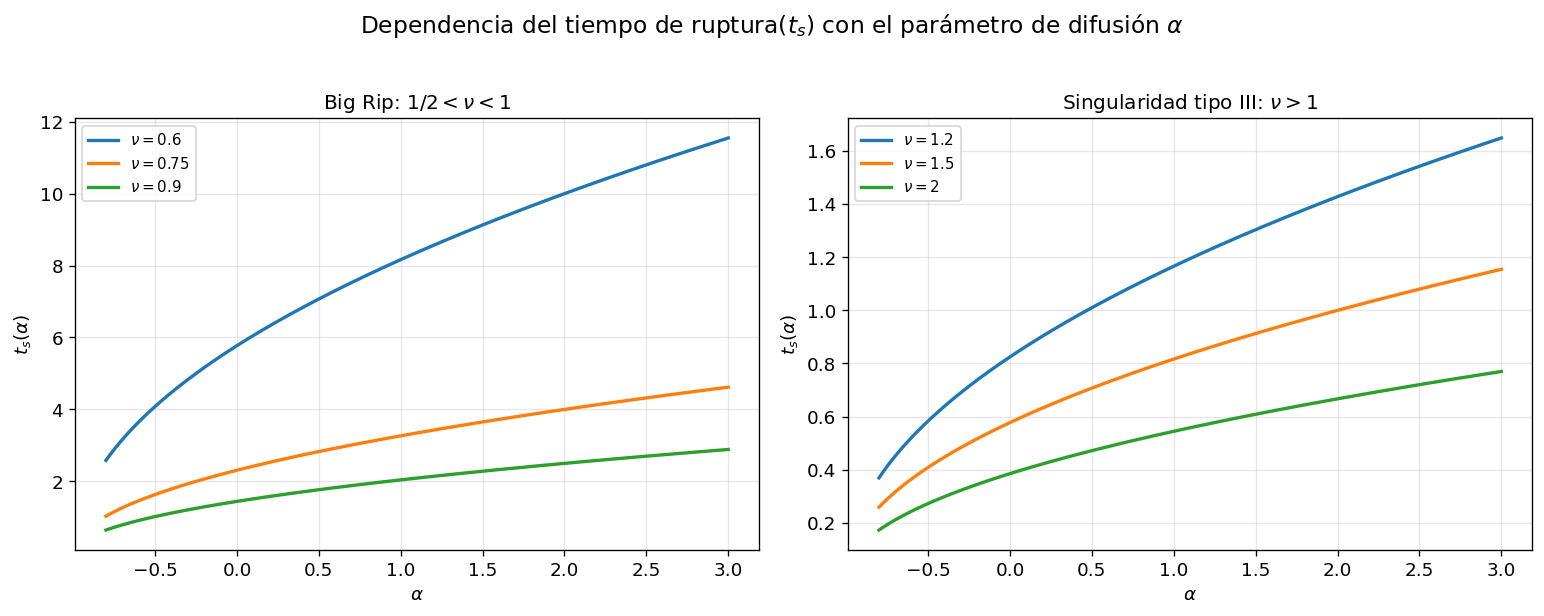

Figura guardada en: figures/tesis_phantom_ug/ug_tiempo_critico_vs_alpha_combinado.pdf


In [22]:
plot_singular_time_combined(
    nu_values_big_rip=[
        0.6,
        0.75,
        0.9,
    ],
    nu_values_type_iii=[
        1.2,
        1.5,
        2.0,
    ],
    filename="ug_tiempo_critico_vs_alpha_combinado.pdf",
    alpha_min=-0.8,
    alpha_max=3.0,
    n_alpha=400,
    A=A,
    rho0=RHO0,
    t0=T0,
)


## 9. Archivos generados

Al ejecutar todas las celdas, las figuras se guardan en la carpeta

```text
figures/tesis_phantom_ug/
```

Los dos archivos nuevos para el tiempo singular son:

```text
ug_tiempo_singular_vs_alpha_big_rip.pdf
ug_tiempo_singular_vs_alpha_tipo_III.pdf
```

Los gráficos principales con \(\dot H\) incorporado son:

```text
ug_intervalo_nu_menor_0_con_hdot.pdf
ug_intervalo_nu_igual_0_con_hdot.pdf
```
